# Q1b: Does the Q1 curve survive a score-margin control? (2025-26)

Notebook 01 found a convex adjusted curve: within a team, games with more threes had slightly *worse* results.
The suspected cause was game state (teams chase games with threes when trailing), which the box score cannot see.
Here we use the 2025-26 play-by-play, which has the running score, to test that.

Plan, fixed before looking at results:
1. **Mechanism check (shot level):** do teams actually shoot a higher share of threes when trailing?
2. **Re-fit the Q1 models on 2025-26 only**, without and with a control for the team's score margin at the time of its shots.
3. **Clean-timing design:** first-half 3PA -> second-half margin, controlling for halftime margin, so the outcome comes after the choice.

Caution on step 2: average in-game margin is partly an *outcome* of the game (it correlates ~0.87 with the final margin), so controlling for it removes real effects of threes too. It is a robustness check, not the final word. Step 3 avoids that problem.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from src.features import load_team_games, load_pbp_shots, vertex_ci, PROCESSED
plt.rcParams['figure.dpi'] = 110
s = load_pbp_shots()
g = load_team_games(); g = g[g.SEASON == '2025-26'].copy(); g['GAME_ID'] = g.GAME_ID.astype(str)
print(f'{len(s):,} shots, {s.GAME_ID.nunique()} games, {int(s.IS3.sum()):,} threes (box score: {int(g.FG3A.sum()):,})')

233,632 shots, 1315 games, 96,813 threes (box score: 96,813)


## 1. Do trailing teams shoot more threes?

,shots,share_3,fg3_pct,se
STATE,,,,
trail 15+,26025,0.423,0.352,0.003
trail 10-14,20049,0.409,0.349,0.003
trail 5-9,33168,0.413,0.360,0.003
trail 1-4,38008,0.411,0.359,0.003
tied,12494,0.399,0.360,0.004
lead 1-4,34816,0.411,0.364,0.003
lead 5-9,28954,0.413,0.360,0.003
lead 10-14,17357,0.413,0.363,0.004
lead 15+,22761,0.434,0.360,0.003


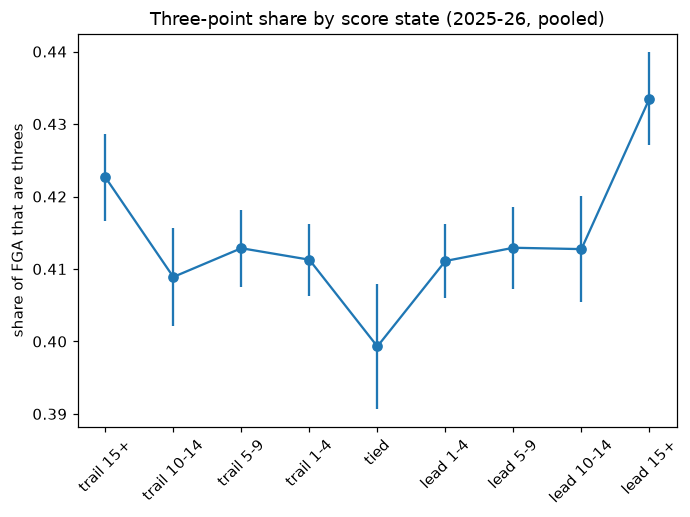

In [2]:
bins = [-80, -15, -10, -5, -1, 0, 4, 9, 14, 80]
labels = ['trail 15+', 'trail 10-14', 'trail 5-9', 'trail 1-4', 'tied', 'lead 1-4', 'lead 5-9', 'lead 10-14', 'lead 15+']
s['STATE'] = pd.cut(s.MARGIN_BEFORE, bins, labels=labels)
t = s.groupby('STATE', observed=True).agg(shots=('IS3', 'size'), share_3=('IS3', 'mean'))
t['fg3_pct'] = s[s.IS3 == 1].groupby('STATE', observed=True).MADE.mean()
t['se'] = np.sqrt(t.share_3 * (1 - t.share_3) / t.shots)
display(t.round(3))
plt.errorbar(range(len(t)), t.share_3, yerr=1.96 * t.se, fmt='o-'); plt.xticks(range(len(t)), t.index, rotation=45)
plt.ylabel('share of FGA that are threes'); plt.title('Three-point share by score state (2025-26, pooled)'); plt.tight_layout(); plt.show()

That is pooled across teams, and good teams lead more and also shoot more threes. The sharper test compares a team with itself *within the same game*: subtract each team-game's own mean from shot type, margin and elapsed time, then regress.

In [3]:
d = s.copy()
d['TG'] = d.GAME_ID + '_' + d.TEAM_ID.astype(str)
d['M'] = d.MARGIN_BEFORE.clip(-20, 20) / 10          # per 10 points, capped
d['T'] = d.SEC_ELAPSED / 2880
d['LATE_CLOSE'] = ((d.SEC_ELAPSED >= 2880 - 300) & (d.MARGIN_BEFORE.abs() <= 5)).astype(int)
cols = ['IS3', 'M', 'T', 'LATE_CLOSE']
w = d[cols] - d.groupby('TG')[cols].transform('mean')
m = smf.ols('IS3 ~ M + T + LATE_CLOSE - 1', data=w).fit(cov_type='cluster', cov_kwds={'groups': d.TG})
print('Within team-game: change in P(shot is a three) per +10 points of margin (capped at +-20)')
pd.DataFrame({'coef': m.params, 'se': m.bse, 'p': m.pvalues}).round(4)

Within team-game: change in P(shot is a three) per +10 points of margin (capped at +-20)


,coef,se,p
M,0.0016,0.0017,0.3384
T,0.0059,0.0037,0.1115
LATE_CLOSE,-0.0115,0.0063,0.0670


## 2. Re-fit the Q1 models on 2025-26 with and without a margin control

In [4]:
key = ['GAME_ID', 'TEAM_ID']
a = s.groupby(key).agg(AVG_MARGIN=('MARGIN_BEFORE', 'mean')).reset_index()
b = s[s.IS3 == 1].groupby(key).agg(AVG_MARGIN_3=('MARGIN_BEFORE', 'mean')).reset_index()
d = g.merge(a, on=key).merge(b, on=key, how='left')
d['AVG_MARGIN_3'] = d.AVG_MARGIN_3.fillna(d.AVG_MARGIN)
fe = 'C(TEAM_SEASON) + OPP_STRENGTH + HOME'
def fit(f, kind):
    mod = smf.logit if kind == 'logit' else smf.ols
    return mod(f, data=d).fit(disp=0, cov_type='cluster', cov_kwds={'groups': d.GAME_ID})
specs = {'no margin control': 'FG3A + FG3A_SQ',
         'control: avg margin at own shots': 'FG3A + FG3A_SQ + AVG_MARGIN',
         'control: avg margin at own threes': 'FG3A + FG3A_SQ + AVG_MARGIN_3'}
rows, models = [], {}
for kind, y in [('ols', 'MARGIN'), ('logit', 'WIN')]:
    for k, v in specs.items():
        mm = fit(f'{y} ~ {v} + {fe}', kind); models[(kind, k)] = mm
        est, lo, hi = vertex_ci(mm.params, mm.cov_params(), 'FG3A', 'FG3A_SQ')
        rows.append(dict(outcome=y, spec=k, b_FG3A=mm.params['FG3A'], b_SQ=mm.params['FG3A_SQ'], se_SQ=mm.bse['FG3A_SQ'],
                         p_SQ=mm.pvalues['FG3A_SQ'], vertex=est, ci_lo=lo, ci_hi=hi))
res = pd.DataFrame(rows).set_index(['outcome', 'spec']); res.round(4)

b_FG3A    b_SQ   se_SQ    p_SQ  \
outcome spec                                                                
MARGIN  no margin control                 -0.4011  0.0068  0.0039  0.0848   
        control: avg margin at own shots  -0.2380  0.0030  0.0021  0.1545   
        control: avg margin at own threes -0.2375  0.0031  0.0021  0.1404   
WIN     no margin control                 -0.0656  0.0008  0.0006  0.1898   
        control: avg margin at own shots  -0.0570  0.0004  0.0008  0.5701   
        control: avg margin at own threes -0.0597  0.0005  0.0008  0.5091   

                                            vertex     ci_lo     ci_hi  
outcome spec                                                            
MARGIN  no margin control                  29.6047  -18.1760   62.7934  
        control: avg margin at own shots   39.7082    7.4334   74.7966  
        control: avg margin at own threes  38.1832   12.2823   67.8279  
WIN     no margin control                  41.5863   -1.2224   87.8204  
        control: avg margin at own shots   65.6808 -176.2735  261.6845  
        control: avg margin at own threes  59.3208 -152.9295  233.7122

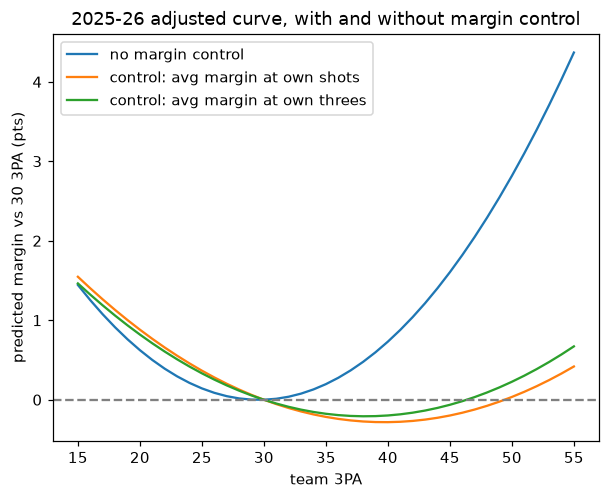

Team-games with FG3A < 20: 13  | > 50: 82 (few observations at the ends)


In [5]:
# Shape of the fitted curve (OLS margin), relative to 30 3PA
xs = np.arange(15, 56)
for k in specs:
    mm = models[('ols', k)]
    plt.plot(xs, mm.params['FG3A'] * xs + mm.params['FG3A_SQ'] * xs**2 - (mm.params['FG3A'] * 30 + mm.params['FG3A_SQ'] * 900), label=k)
plt.axhline(0, c='gray', ls='--'); plt.xlabel('team 3PA'); plt.ylabel('predicted margin vs 30 3PA (pts)')
plt.title('2025-26 adjusted curve, with and without margin control'); plt.legend(); plt.show()
print('Team-games with FG3A < 20:', (d.FG3A < 20).sum(), ' | > 50:', (d.FG3A > 50).sum(), '(few observations at the ends)')

## 3. Clean timing: first-half 3PA -> second-half margin

First-half threes come before the second half, so the outcome cannot cause them. Controls: halftime margin, average first-half margin, first-half FGA.

In [6]:
p = pd.read_parquet(PROCESSED / 'pbp_2025-26.parquet')
for c in ['scoreHome', 'scoreAway']: p[c] = pd.to_numeric(p[c], errors='coerce')
h1 = p[p.period <= 2].groupby('gameId').agg(h=('scoreHome', 'max'), a=('scoreAway', 'max')).reset_index().rename(columns={'gameId': 'GAME_ID'})
d1 = s[s.SEC_ELAPSED < 1440].groupby(key).agg(H1_FG3A=('IS3', 'sum'), H1_FGA=('IS3', 'size'), H1_AVG_MARGIN=('MARGIN_BEFORE', 'mean')).reset_index()
q = g.merge(d1, on=key).merge(h1, on='GAME_ID')
q['HT_MARGIN'] = np.where(q.HOME == 1, q.h - q.a, q.a - q.h)
q['H2_MARGIN'] = q.MARGIN - q.HT_MARGIN
q['H1_SQ'] = q.H1_FG3A ** 2
f = 'H2_MARGIN ~ H1_FG3A + H1_SQ + H1_FGA + HT_MARGIN + H1_AVG_MARGIN + C(TEAM_SEASON) + OPP_STRENGTH + HOME'
mh = smf.ols(f, data=q).fit(cov_type='cluster', cov_kwds={'groups': q.GAME_ID})
est, lo, hi = vertex_ci(mh.params, mh.cov_params(), 'H1_FG3A', 'H1_SQ')
print(f"Quadratic: H1 3PA {mh.params['H1_FG3A']:+.3f} (se {mh.bse['H1_FG3A']:.3f}); squared {mh.params['H1_SQ']:+.5f} (p={mh.pvalues['H1_SQ']:.3f}); vertex {est:.1f} [{lo:.1f}, {hi:.1f}]")
print(f"Mean H1 3PA {q.H1_FG3A.mean():.1f}, sd {q.H1_FG3A.std():.1f}")
mh2 = smf.ols(f.replace(' + H1_SQ', ''), data=q).fit(cov_type='cluster', cov_kwds={'groups': q.GAME_ID})
ci = mh2.conf_int().loc['H1_FG3A']
print(f"Linear: {mh2.params['H1_FG3A']:+.3f} pts of 2nd-half margin per extra 1st-half 3PA (95% CI {ci[0]:+.3f} to {ci[1]:+.3f}), p={mh2.pvalues['H1_FG3A']:.3f}, holding H1 FGA fixed")

Quadratic: H1 3PA -0.761 (se 0.309); squared +0.01906 (p=0.017); vertex 20.0 [15.9, 26.6]
Mean H1 3PA 18.7, sd 4.3
Linear: -0.031 pts of 2nd-half margin per extra 1st-half 3PA (95% CI -0.149 to +0.088), p=0.613, holding H1 FGA fixed


## Reading the results

- **Mechanism not supported.** Teams shoot about 41-42% threes whatever the score (a slight rise at 15+ down or up). Within the same game, a team's three-point share barely moves with its margin (+0.16 points of share per +10 points of lead, p = 0.34). Trailing teams are not shooting noticeably more threes, so 'chasing the game' is not a good explanation for the convex curve.
- **The curve is weak in 2025-26 alone.** Even without a margin control the squared term is only borderline (margin p = 0.085, win p = 0.19), and the margin control roughly halves it (0.0068 -> 0.0030) and leaves it non-significant. But the single-season estimates are noisy and their confidence intervals overlap, so this does not prove the margin control is what shrank it.
- **No clear optimum in any specification.** The vertex is unstable (about 30 to 66 with CIs that include implausible values).
- **Clean-timing check:** first-half 3PA has no linear effect on second-half margin (about -0.03 points per extra three, 95% CI -0.15 to +0.09). A U-shaped term appears (p = 0.017, minimum near 20 first-half 3PA, tails about +1 point), but it is one nominal p-value among several tests and should be treated as exploratory.
- **Bottom line:** Q1 stays inconclusive in the sense that there is no evidence of a best number of threes, and the earlier 'game state' explanation is not backed by the shot-level data.